# Operating curves, crossover and labor economics
Executed against the delivered CSV results. See ../docs/METHODS.md for model assumptions.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root=Path('..')
s=pd.read_csv(root/'results/summary.csv')
print(json.loads((root/'results/validation.json').read_text()))


{'main_replications': 2160, 'supplemental_replications': 740, 'experiment_cells': 290, 'replications_per_cell': 10, 'one_picker_verification_cases': 320, 'max_relative_verification_error': 9.347172302070875e-15, 'stream_recycled': False, 'time_conservation': True, 'order_flow_conservation': True, 'single_picker_blocking_zero': True, 'passing_blocking_zero': True}


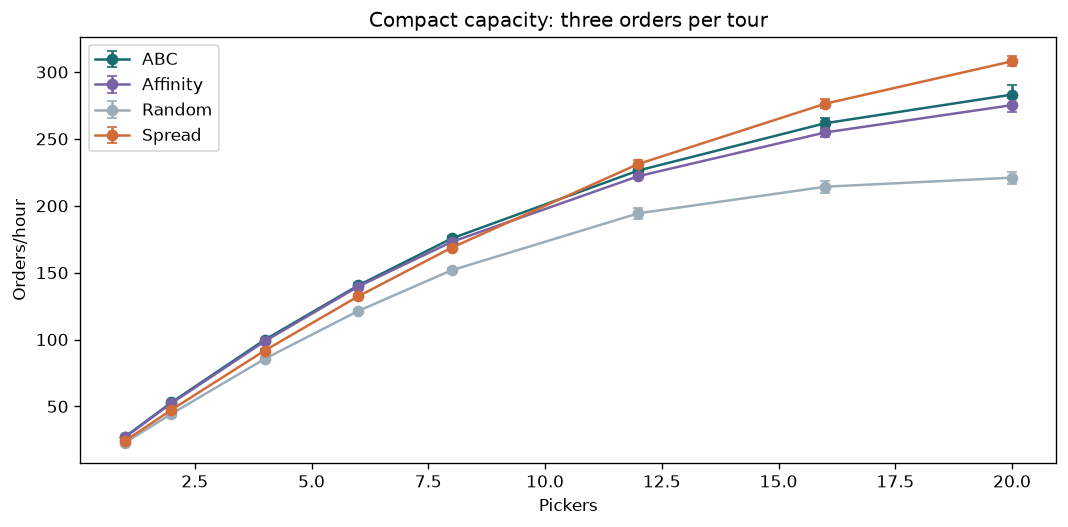

In [2]:
d=s.query("scope=='compact800' and family=='baseline'")
fig,ax=plt.subplots(figsize=(9,4.5))
colors={'ABC':'#176b70','Spread':'#d16b38','Affinity':'#7961a5','Random':'#9aadb8'}
for policy,g in d.groupby('policy'):
    g=g.sort_values('pickers')
    ax.errorbar(g.pickers,g.orders_per_hour,yerr=g.orders_per_hour_high-g.orders_per_hour,fmt='-o',label=policy,color=colors[policy],capsize=3)
ax.set(xlabel='Pickers',ylabel='Orders/hour',title='Compact capacity: three orders per tour')
ax.legend(); fig.tight_layout()


In [3]:
paired=pd.read_csv(root/'results/paired_throughput.csv')
print(paired.query("scope=='compact800' and family=='baseline'").to_string(index=False))
print('At 12 pickers the pointwise interval is positive, but the simultaneous interval includes zero. Sustained simultaneous evidence begins at 16.')


     scope   family  pickers  spread_minus_abc    ci_low   ci_high  simultaneous_low  simultaneous_high
compact800 baseline        1           -3.0375 -3.426244 -2.648756         -3.646955          -2.428045
compact800 baseline        2           -5.5500 -6.216761 -4.883239         -6.595318          -4.504682
compact800 baseline        4           -8.0625 -8.834311 -7.290689         -9.272511          -6.852489
compact800 baseline        6           -8.1000 -9.327364 -6.872636        -10.024206          -6.175794
compact800 baseline        8           -6.9000 -9.215260 -4.584740        -10.529761          -3.270239
compact800 baseline       12            4.8750  0.571696  9.178304         -1.871528          11.621528
compact800 baseline       16           14.5875  8.572477 20.602523          5.157417          24.017583
compact800 baseline       20           24.9000 16.790671 33.009329         12.186558          37.613442
At 12 pickers the pointwise interval is positive, but the simult

In [4]:
economics=pd.read_csv(root/'results/batch_staffing_economics.csv')
print(economics[['scope','policy','k','pickers','simulated_labor_hours_1000','simulated_labor_low','simulated_labor_high','oldest_order_minutes']].round(2).to_string(index=False))


     scope policy  k  pickers  simulated_labor_hours_1000  simulated_labor_low  simulated_labor_high  oldest_order_minutes
compact800    ABC  3       12                       79.69                78.21                 81.17                  8.62
compact800    ABC  5        8                       53.03                52.06                 54.01                 11.61
compact800 Spread  3       12                       79.73                78.30                 81.15                  9.15
compact800 Spread  5        8                       52.92                51.94                 53.91                 12.75
coverage90    ABC  3        8                      242.77               235.93                249.61                 34.33
coverage90    ABC  5        6                      183.20               177.33                189.07                 47.40
coverage90 Spread  3       12                      365.97               354.30                377.65                 39.90
coverage90 Sprea

In [5]:
print(pd.read_csv(root/'results/density_paired.csv').round(3).to_string(index=False))
print('115-aisle extension: 138 total pickers equals 12 pickers per ten aisles. Do not equate it with 12 total pickers.')


 pickers  pickers_per_10_aisles  spread_minus_abc  ci_low  ci_high
      23                    2.0           -19.950 -21.201  -18.699
      46                    4.0           -32.925 -34.967  -30.883
      69                    6.0           -36.412 -38.669  -34.156
      92                    8.0           -27.300 -31.977  -22.623
     138                   12.0            44.700  34.027   55.373
     184                   16.0            72.862  56.694   89.031
     230                   20.0            82.875  66.703   99.047
115-aisle extension: 138 total pickers equals 12 pickers per ten aisles. Do not equate it with 12 total pickers.
